# Exploratory Data Analysis (EDA): Digitalisation in EU Countries

**Goal of this notebook.** Understand the data before building models: how the dataset is structured, which values are missing, how the indicators are distributed, how they changed between 2021 and 2025, how countries rank, and which variables move together.

**How to use it.** Run one cell at a time with `Shift + Enter` and read the text above each cell *before* running it. After each chart, stop and look at it: EDA is about asking questions, not just producing images. At the end there is a space to write down what you noticed.

**Contents**
0. Setup and data dictionary
1. Loading and structure of the data (`.shape`, `.info()`, `.describe()`)
2. Missing values and quality checks
3. Distributions of the indicators
4. Evolution 2021 → 2025
5. Country rankings by dimension
6. Correlation matrix
7. GDP per capita and business digitalisation
8. What I noticed

## 0. Setup

This cell imports the libraries and locates the project's root folder (the one containing `data/`), so the notebook works whether it is launched from `notebooks/` or from the root folder. Charts are also saved to `outputs/figures/`: you will need them for the README.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 2)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# Project root = the folder that contains data/processed
ROOT = next((p for p in [Path(".."), Path(".")] if (p / "data" / "processed").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Cannot find data/processed: open the project from its root folder.")

FIG_DIR = ROOT / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    """Save the current chart in outputs/figures/ (call it BEFORE plt.show())."""
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

### Data dictionary

The indicators are grouped into the four dimensions of the Digital Decade. The **Business** dimension contains the four indicators that, according to the README, will be used to build the *target*. **Unicorns** (start-ups valued at over USD 1 billion) are kept out of the dimensions: they are an absolute count, not a percentage, so they depend on the size of the country and have a very skewed distribution.

| Dimension | Variable | Meaning | Unit |
|---|---|---|---|
| People | `skills_basic` | People with at least basic digital skills | % of people |
| People | `skills_above` | People with above-basic digital skills | % of people |
| People | `ict_specialists` | ICT specialists as a share of total employment | % of employed |
| Infrastructure | `fttp` | Households reached by fibre to the premises | % of households |
| Infrastructure | `vhcn` | Households reached by very high capacity networks | % of households |
| Infrastructure | `gbit5g` | 5G coverage | % of households |
| Business | `sme_digital_intensity` | SMEs with at least a basic level of digital intensity | % of SMEs |
| Business | `cloud` | Enterprises using cloud services | % of enterprises |
| Business | `ai` | Enterprises using artificial intelligence technologies | % of enterprises |
| Business | `erp` | Enterprises using ERP software | % of enterprises |
| (outside dimensions) | `unicorns` | Number of unicorns in the country | count |
| Public services | `egov_citizens` | Digital public services for citizens | score 0-100 |
| Public services | `egov_business` | Digital public services for businesses | score 0-100 |
| World Bank | `gdp_pc_ppp` | GDP per capita, purchasing power parity | dollars |
| World Bank | `tertiary_enrol` | Tertiary education enrolment | % gross |
| World Bank | `rnd_gdp` | Research and development expenditure | % of GDP |
| World Bank | `urban_pop` | Urban population | % |
| World Bank | `services_gdp` | Services, value added | % of GDP |

Note: the World Bank variables are those of the **previous** year relative to the row (1-year lag), as described in the README.

In [2]:
DIMENSIONS = {
    "People": ["skills_basic", "skills_above", "ict_specialists"],
    "Infrastructure": ["fttp", "vhcn", "gbit5g"],
    "Business": ["sme_digital_intensity", "cloud", "ai", "erp"],
    "Public services": ["egov_citizens", "egov_business"],
}
INDICATORS = [c for cols in DIMENSIONS.values() for c in cols] + ["unicorns"]

# Colours by dimension (a palette that is also readable with colour-vision deficiencies)
DIM_COLORS = {"People": "#0072B2", "Infrastructure": "#E69F00",
              "Business": "#009E73", "Public services": "#CC79A7", "Other": "#7F7F7F"}

def dim_of(col):
    """Return the dimension an indicator belongs to."""
    return next((d for d, cols in DIMENSIONS.items() if col in cols), "Other")

LABELS = {
    "skills_basic": "Basic digital skills", "skills_above": "Above-basic digital skills",
    "ict_specialists": "ICT specialists (% employed)", "fttp": "Fibre (FTTP)",
    "vhcn": "Very high capacity networks", "gbit5g": "5G coverage",
    "sme_digital_intensity": "SMEs with basic digital intensity", "cloud": "Enterprises using cloud",
    "ai": "Enterprises using AI", "erp": "Enterprises using ERP", "unicorns": "Unicorns (count)",
    "egov_citizens": "Digital public services: citizens", "egov_business": "Digital public services: business",
    "log_gdp_pc_ppp": "GDP per capita (log)", "tertiary_enrol": "Tertiary enrolment",
    "rnd_gdp": "R&D spending (% GDP)", "urban_pop": "Urban population",
    "services_gdp": "Services (% GDP)",
}

COUNTRY_NAMES = {
    "AT": "Austria", "BE": "Belgium", "BG": "Bulgaria", "CY": "Cyprus", "CZ": "Czechia",
    "DE": "Germany", "DK": "Denmark", "EE": "Estonia", "EL": "Greece", "ES": "Spain",
    "FI": "Finland", "FR": "France", "HR": "Croatia", "HU": "Hungary", "IE": "Ireland",
    "IT": "Italy", "LT": "Lithuania", "LU": "Luxembourg", "LV": "Latvia", "MT": "Malta",
    "NL": "Netherlands", "PL": "Poland", "PT": "Portugal", "RO": "Romania",
    "SE": "Sweden", "SI": "Slovenia", "SK": "Slovakia",
}

## 1. Loading and structure of the data

The first thing to do with any dataset: load it and look at it. The cell looks for `panel_full.csv` (DESI + World Bank); if it cannot find it, it uses `desi_panel.csv` and warns you, skipping the parts that need World Bank data.

In [3]:
candidates = [ROOT / "data" / "processed" / "panel_full.csv",
              ROOT / "data" / "processed" / "desi_panel.csv"]
path = next((p for p in candidates if p.exists()), None)
if path is None:
    raise FileNotFoundError("No file in data/processed: run build_dataset.py and add_worldbank.py first.")

df = pd.read_csv(path)
HAS_WB = "gdp_pc_ppp" in df.columns
print(f"Loaded file: {path.name}")
if not HAS_WB:
    print("WARNING: World Bank data is missing. Run add_worldbank.py: "
          "the cells that use it will be skipped.")

df.head()

Loaded file: panel_full.csv


,country,year,skills_basic,skills_above,ict_specialists,fttp,vhcn,gbit5g,sme_digital_intensity,cloud,ai,erp,unicorns,egov_citizens,egov_business,iso3,gdp_pc_ppp,population,rnd_gdp,services_gdp,tertiary_enrol,urban_pop,log_gdp_pc_ppp,log_population
0,AT,2021,63.33,33.28,4.5,26.62,45.37,76.80,64.43,28.76,8.83,45.17,4.0,75.78,81.43,AUT,60276.33,8.92e+06,3.21,62.81,88.71,68.54,11.01,16.00
1,AT,2023,64.68,32.04,5.3,40.97,67.62,96.03,57.93,35.56,10.79,40.13,4.0,80.72,82.86,AUT,65694.46,9.04e+06,3.18,62.44,94.51,69.00,11.09,16.02
2,AT,2025,69.77,34.26,5.4,50.88,76.26,99.84,72.99,41.70,29.95,37.52,4.0,83.73,88.80,AUT,63787.99,9.18e+06,3.26,63.97,92.61,69.47,11.06,16.03
3,BE,2021,54.23,26.34,5.6,10.09,68.92,4.25,65.35,46.87,10.32,57.23,6.0,72.19,81.01,BEL,57333.54,1.15e+07,3.37,70.34,79.50,87.30,10.96,16.26
4,BE,2023,59.39,28.26,5.4,25.00,91.20,40.35,74.46,47.69,13.81,59.52,7.0,82.33,91.59,BEL,62602.93,1.17e+07,3.20,69.44,83.57,87.49,11.04,16.27


**`.shape`** gives (rows, columns). With 27 countries and 3 years you expect **81 rows**. There are 24 columns with the World Bank data, 15 without.

In [4]:
print(df.shape)

(81, 24)


**`.info()`** lists the columns with their data type (`float64` = decimal number, `int64` = integer, `object`/`str` = text) and the number of **non-null** values. If a non-null count is lower than the total number of rows, that column has missing values. `country` should be text, all indicators numeric.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   country                81 non-null     str    
 1   year                   81 non-null     int64  
 2   skills_basic           81 non-null     float64
 3   skills_above           81 non-null     float64
 4   ict_specialists        81 non-null     float64
 5   fttp                   81 non-null     float64
 6   vhcn                   81 non-null     float64
 7   gbit5g                 81 non-null     float64
 8   sme_digital_intensity  81 non-null     float64
 9   cloud                  81 non-null     float64
 10  ai                     81 non-null     float64
 11  erp                    81 non-null     float64
 12  unicorns               81 non-null     float64
 13  egov_citizens          81 non-null     float64
 14  egov_business          81 non-null     float64
 15  iso3               

**`.describe()`** summarises each variable: mean, standard deviation (`std`), minimum, quartiles and maximum. What to look for: do the **minimum and maximum** make sense (percentages between 0 and 100)? A mean very different from the median (`50%`) signals a skewed distribution. A large `std` relative to the mean indicates strong variability across countries.

In [6]:
df[INDICATORS].describe().T.rename(index=LABELS)

,count,mean,std,min,25%,50%,75%,max
Basic digital skills,81.0,58.31,12.54,27.73,50.42,59.15,66.18,83.61
Above-basic digital skills,81.0,29.55,11.30,7.73,21.54,28.13,35.68,55.61
ICT specialists (% employed),81.0,5.07,1.47,2.40,4.30,4.80,5.70,8.90
Fibre (FTTP),81.0,67.67,21.79,10.09,51.92,76.03,83.92,96.25
Very high capacity networks,81.0,78.87,16.65,19.81,69.12,81.12,93.53,100.00
5G coverage,81.0,76.39,30.90,0.00,59.30,94.01,99.47,100.00
SMEs with basic digital intensity,81.0,61.41,16.26,22.23,51.97,59.99,74.35,94.04
Enterprises using cloud,81.0,41.49,16.35,9.93,29.04,40.73,53.07,73.12
Enterprises using AI,81.0,12.22,9.21,1.38,5.19,9.92,15.19,42.03
Enterprises using ERP,81.0,40.19,11.69,16.81,31.86,39.85,48.27,67.26


## 2. Missing values and quality checks

Before analysing, check that the dataset is clean: missing values, duplicate rows, a complete panel (every country must appear in all 3 years). If there are missing values in the World Bank variables, the second part of the cell shows which countries and years they belong to: write them down, they will need to be documented in the README.

In [7]:
missing = df.isna().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.any() else "  none")

print("\nDuplicate rows (country, year):", df.duplicated(["country", "year"]).sum())
print("Countries:", df["country"].nunique(), "| Years:", [int(y) for y in sorted(df["year"].unique())])
print("Observations per country (should all be 3):", df.groupby("country").size().unique())

if missing.any():
    cols_missing = list(missing[missing > 0].index)
    display(df.loc[df.isna().any(axis=1), ["country", "year"] + cols_missing])

Missing values per column:
  none

Duplicate rows (country, year): 0
Countries: 27 | Years: [2021, 2023, 2025]
Observations per country (should all be 3): [3]


## 3. Distributions of the indicators

A histogram shows how values are distributed: how many countries fall into each band. Each chart below uses the 81 observations (countries and years together). What to look for:

- **Skewed distributions**: a few observations with very high values (right tail), as is typical for unicorns. A logarithmic transformation might be needed later.
- **Ceiling effect**: indicators such as 5G coverage or very high capacity networks pile up near 100%, because they cannot grow beyond it.
- **Multiple peaks**: they may indicate groups of different countries (useful for clustering).

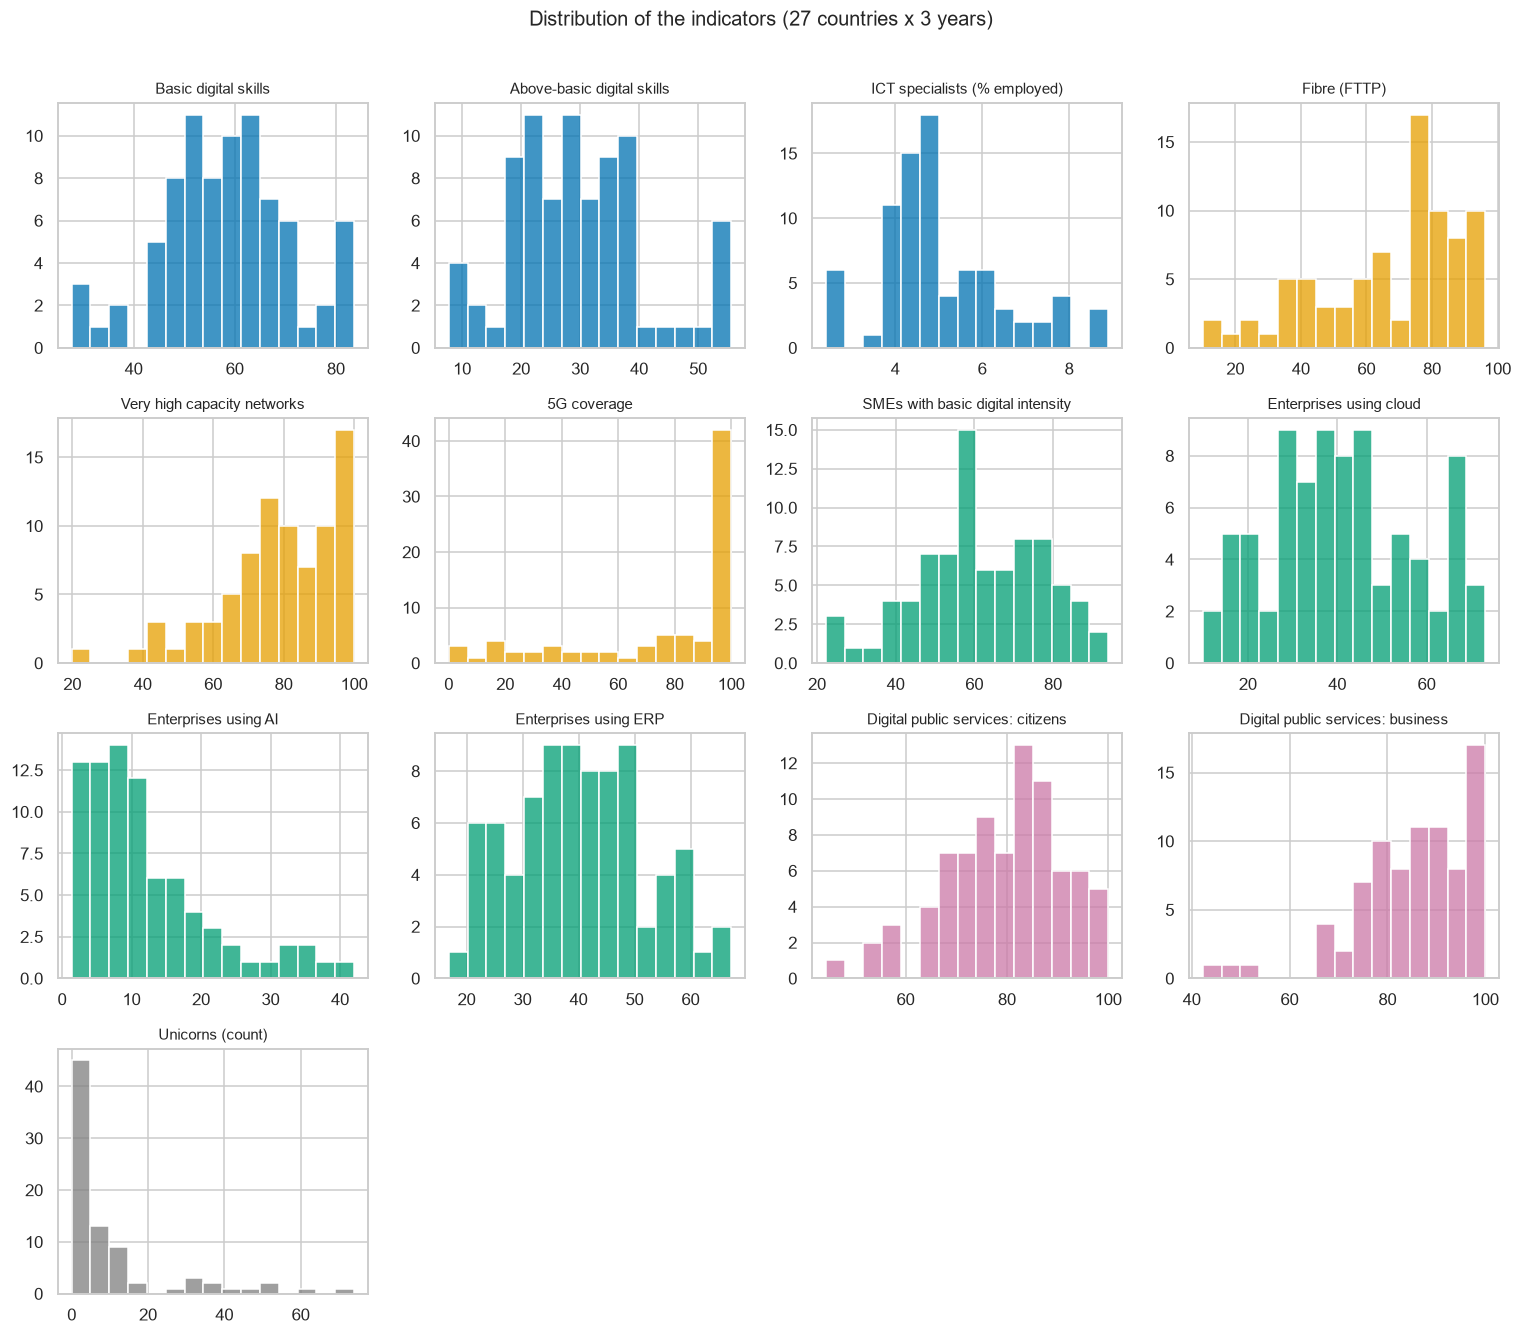

In [8]:
n = len(INDICATORS)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3 * nrows))

for ax, col in zip(axes.flat, INDICATORS):
    sns.histplot(df[col], bins=15, color=DIM_COLORS[dim_of(col)], ax=ax)
    ax.set_title(LABELS[col], fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in axes.flat[n:]:          # hide the empty panels at the bottom
    ax.set_visible(False)

fig.suptitle("Distribution of the indicators (27 countries x 3 years)", y=1.01, fontsize=13)
plt.tight_layout()
save_fig("01_distributions")
plt.show()

**Skewness** (`skew`) measures how lopsided a distribution is: close to 0 it is symmetric, **above 1** it has a long right tail (a few very high countries), **below -1** a long left tail (usually a ceiling effect). Check whether the numbers confirm what you saw in the charts.

In [9]:
df[INDICATORS].skew().sort_values(ascending=False).rename(index=LABELS).round(2).to_frame("skewness")

,skewness
Unicorns (count),2.24
Enterprises using AI,1.39
ICT specialists (% employed),0.67
Above-basic digital skills,0.47
Enterprises using ERP,0.20
Enterprises using cloud,0.13
Basic digital skills,-0.13
SMEs with basic digital intensity,-0.21
Digital public services: citizens,-0.59
Fibre (FTTP),-0.76


## 4. Evolution 2021 → 2025

We compute the **mean of the 27 countries** for each year and the change between 2021 and 2025. Two caveats:

- it is a simple mean, **not population-weighted**: Malta counts as much as Germany;
- the change is in **percentage points** (pp) for indicators expressed as percentages and in score points for public services; for unicorns it is a count, so it is not comparable and is left out of the chart.

Indicators that are already close to 100% (5G, very high capacity networks) have little room to grow: a small increase does not mean lack of interest, it can be saturation.

In [10]:
means = df.groupby("year")[INDICATORS].mean().T
means["change_pp"] = means[2025] - means[2021]
means["change_%"] = (means[2025] / means[2021] - 1) * 100
means = means.sort_values("change_pp", ascending=False)

display(means.rename(index=LABELS).round(1))

year,2021,2023,2025,change_pp,change_%
5G coverage,45.7,86.4,97.1,51.4,112.7
Fibre (FTTP),56.4,68.5,78.1,21.7,38.5
SMEs with basic digital intensity,55.3,58.3,70.6,15.3,27.7
Very high capacity networks,70.8,79.8,86.1,15.3,21.6
Enterprises using AI,7.7,8.2,20.7,13.0,169.2
Enterprises using cloud,36.4,40.9,47.2,10.8,29.5
Digital public services: citizens,74.6,79.4,84.6,10.0,13.4
Digital public services: business,81.7,85.4,88.6,6.9,8.4
Enterprises using ERP,36.5,41.4,42.7,6.3,17.3
Basic digital skills,56.3,57.6,61.0,4.7,8.4


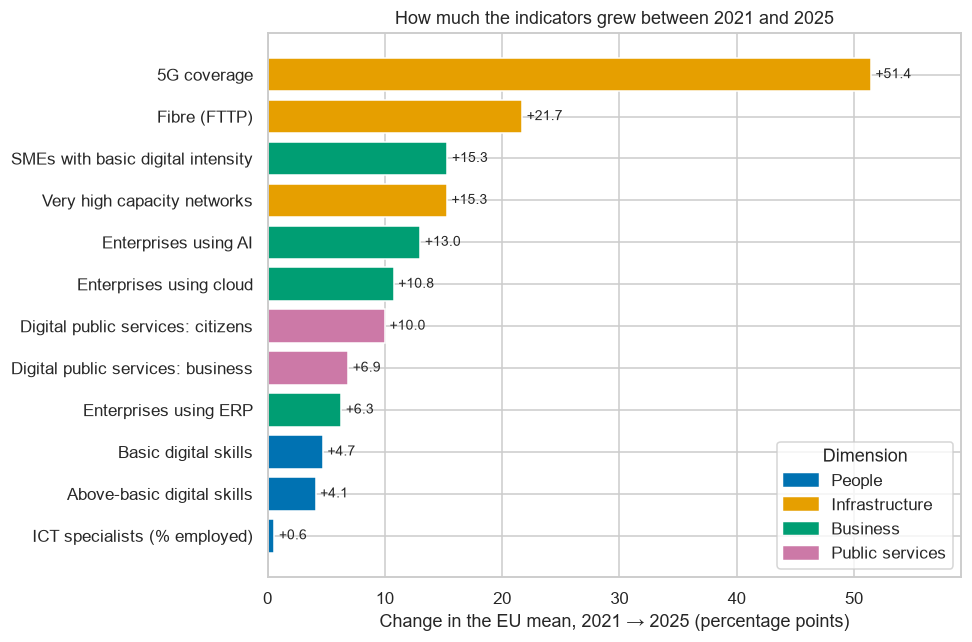

In [11]:
change = means.drop(index="unicorns")["change_pp"].sort_values()   # without unicorns (a count)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh([LABELS[c] for c in change.index], change.values,
               color=[DIM_COLORS[dim_of(c)] for c in change.index])
ax.bar_label(bars, fmt="%+.1f", padding=3, fontsize=9)
ax.set_xlabel("Change in the EU mean, 2021 → 2025 (percentage points)")
ax.set_title("How much the indicators grew between 2021 and 2025")
ax.legend(handles=[Patch(color=DIM_COLORS[d], label=d) for d in DIMENSIONS],
          loc="lower right", title="Dimension")
ax.set_xlim(right=change.max() * 1.15)
plt.tight_layout()
save_fig("02_change_2021_2025")
plt.show()

**Questions to ask yourself:** which indicator grew the most and which the least? Do skills (people) move more slowly than infrastructure and business technologies?

A caution on artificial intelligence: a strong increase may reflect real growth, but also changes in the definition or measurement of the indicator between survey editions. Before drawing conclusions, check the DESI methodological notes (this is one of the limitations already listed in the README).

## 5. Country rankings by dimension

To compare indicators with different units we **standardise** them (z-score: how far a value is from the mean, in standard deviations; 0 = at the mean, +1 = one standard deviation above). Then, for each dimension, we take the **mean of the z-scores** of its indicators. The z-score is computed across all years together, so changes over time remain visible.

The **Business** score (mean of SMEs, cloud, AI, ERP) is the prototype of the project's target variable.

In [12]:
# z-score of each indicator across the whole panel (all years together)
z = (df[INDICATORS] - df[INDICATORS].mean()) / df[INDICATORS].std()

scores = df[["country", "year"]].copy()
for dim, cols in DIMENSIONS.items():
    scores[dim] = z[cols].mean(axis=1)
scores["Overall index"] = scores[list(DIMENSIONS)].mean(axis=1)

scores.head()

,country,year,People,Infrastructure,Business,Public services,Overall index
0,AT,2021,0.11,-1.29,-0.13,-0.32,-0.41
1,AT,2023,0.30,-0.42,-0.18,-0.05,-0.09
2,AT,2025,0.52,-0.06,0.61,0.32,0.35
3,BE,2021,-0.08,-1.86,0.46,-0.49,-0.49
4,BE,2023,0.07,-0.79,0.75,0.38,0.10


The **heatmap** shows the countries in the latest available year, sorted from most to least digitalised according to the overall index. Blue = above the European average, red = below. Look especially at countries whose colours differ a lot from one column to another: they have an unbalanced profile (for example good infrastructure but lagging businesses).

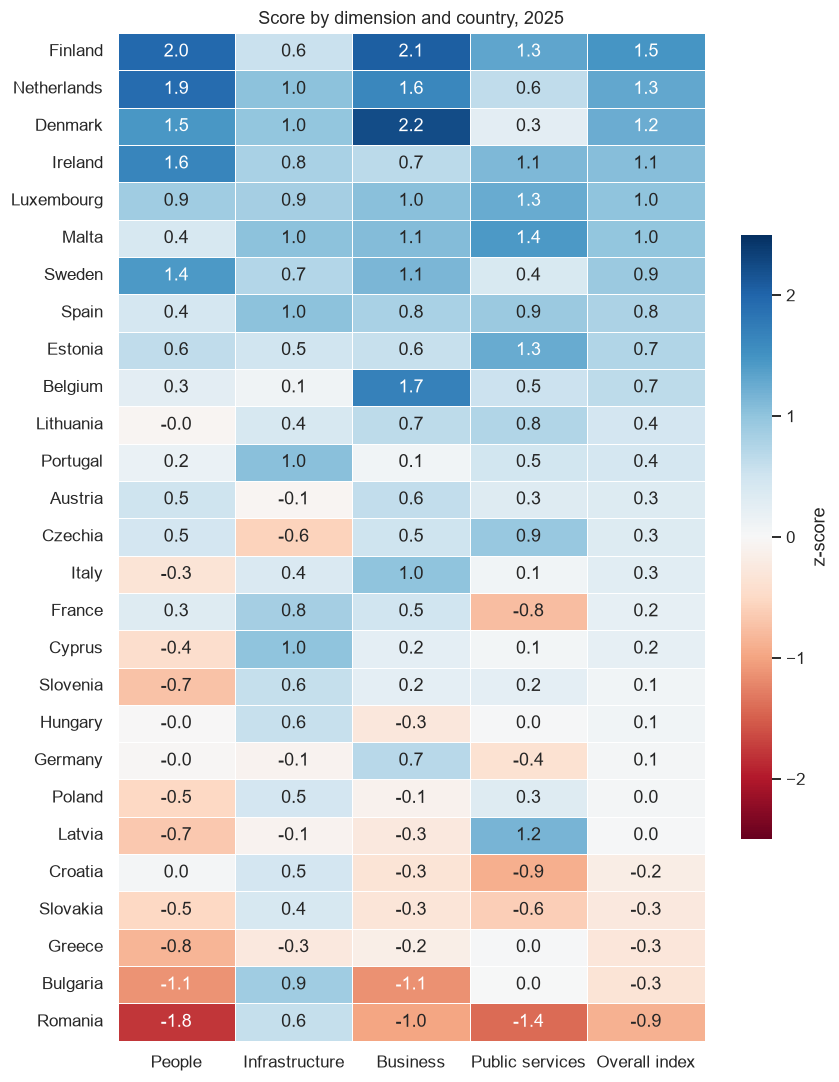

In [13]:
last_year = scores["year"].max()
latest = (scores[scores["year"] == last_year]
          .set_index("country").drop(columns="year")
          .sort_values("Overall index", ascending=False))

fig, ax = plt.subplots(figsize=(8, 10))
sns.heatmap(latest.rename(index=COUNTRY_NAMES), annot=True, fmt=".1f", cmap="RdBu",
            center=0, vmin=-2.5, vmax=2.5, linewidths=0.5, cbar_kws={"label": "z-score", "shrink": 0.6}, ax=ax)
ax.set_ylabel("")
ax.set_title(f"Score by dimension and country, {last_year}")
plt.tight_layout()
save_fig("03_heatmap_dimensions")
plt.show()

In [14]:
print(f"Top and bottom 5 countries by dimension, {last_year}\n")
for dim in list(DIMENSIONS) + ["Overall index"]:
    s = latest[dim].sort_values(ascending=False)
    top = ", ".join(COUNTRY_NAMES[c] for c in s.index[:5])
    bottom = ", ".join(COUNTRY_NAMES[c] for c in s.index[-5:])
    print(f"{dim}\n  top:    {top}\n  bottom: {bottom}\n")

Top and bottom 5 countries by dimension, 2025

People
  top:    Finland, Netherlands, Ireland, Denmark, Sweden
  bottom: Latvia, Slovenia, Greece, Bulgaria, Romania

Infrastructure
  top:    Portugal, Malta, Spain, Netherlands, Cyprus
  bottom: Austria, Latvia, Germany, Greece, Czechia

Business
  top:    Denmark, Finland, Belgium, Netherlands, Sweden
  bottom: Hungary, Slovakia, Croatia, Romania, Bulgaria

Public services
  top:    Malta, Finland, Estonia, Luxembourg, Latvia
  bottom: Germany, Slovakia, France, Croatia, Romania

Overall index
  top:    Finland, Netherlands, Denmark, Ireland, Luxembourg
  bottom: Croatia, Slovakia, Greece, Bulgaria, Romania



### Optional: where does Italy stand?

Italy's rank among the 27 countries in each year (1 = best). Change `"IT"` to another country code to look at a different case (Greece is `"EL"`).

In [15]:
COUNTRY = "IT"
cols = list(DIMENSIONS) + ["Overall index"]
ranks = scores.groupby("year")[cols].rank(ascending=False, method="min").astype(int)
ranks = ranks.assign(country=scores["country"], year=scores["year"])
display(ranks[ranks["country"] == COUNTRY].set_index("year").drop(columns="country"))

,People,Infrastructure,Business,Public services,Overall index
year,,,,,
2021,23,17,9,19,19
2023,21,21,7,24,21
2025,19,21,8,18,15


### Optional: are lagging countries catching up?

We compare the **starting level** (2021) of the Business index with the **change** up to 2025. If the most lagging countries are those growing the most, the points slope downwards from left to right (negative correlation): a sign of **convergence**. Caution: with 27 countries the result is indicative, and it can partly be due to measurement error (a country with an unusually low 2021 value tends to "catch up" through a purely statistical effect).

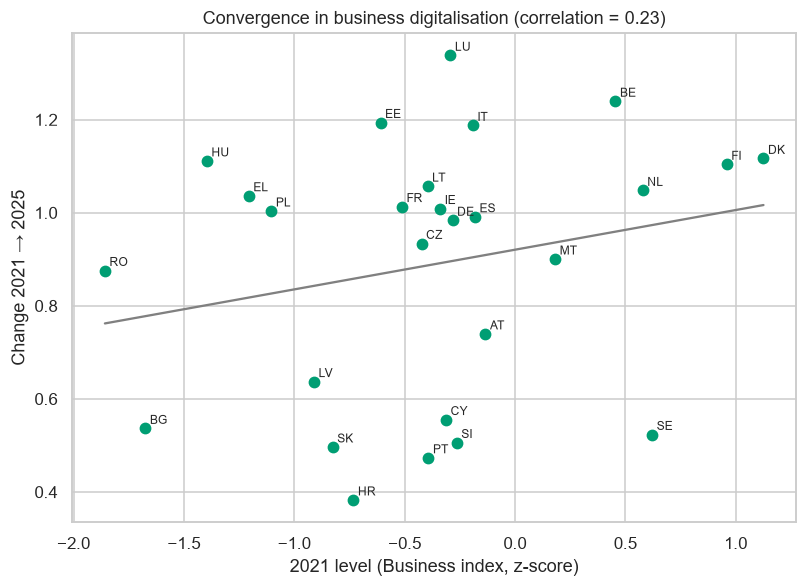

In [16]:
biz = scores.pivot(index="country", columns="year", values="Business")
growth = biz[2025] - biz[2021]
r = biz[2021].corr(growth)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(biz[2021], growth, color=DIM_COLORS["Business"], s=45)
sns.regplot(x=biz[2021], y=growth, scatter=False, ci=None, color="grey", line_kws={"lw": 1.5}, ax=ax)
for c in biz.index:
    ax.annotate(c, (biz.loc[c, 2021], growth[c]), xytext=(3, 3), textcoords="offset points", fontsize=8)
ax.set_xlabel("2021 level (Business index, z-score)")
ax.set_ylabel("Change 2021 → 2025")
ax.set_title(f"Convergence in business digitalisation (correlation = {r:.2f})")
plt.tight_layout()
save_fig("04_convergence_business")
plt.show()

## 6. Correlation matrix

Pearson's correlation (from -1 to +1) measures how much two variables move together in a linear way: +1 they rise together, -1 one rises while the other falls, 0 no linear relationship. How to read it:

- **very intense colours** = strong relationships;
- **many values above 0.8** = **multicollinearity**: the variables carry similar information and models struggle to separate the contribution of each (this is the limitation already mentioned in the README);
- correlation is **not causation**.

The calculation uses all 81 observations together, so differences *between countries* weigh more than differences over time. We show only the lower triangle, because the matrix is symmetric.

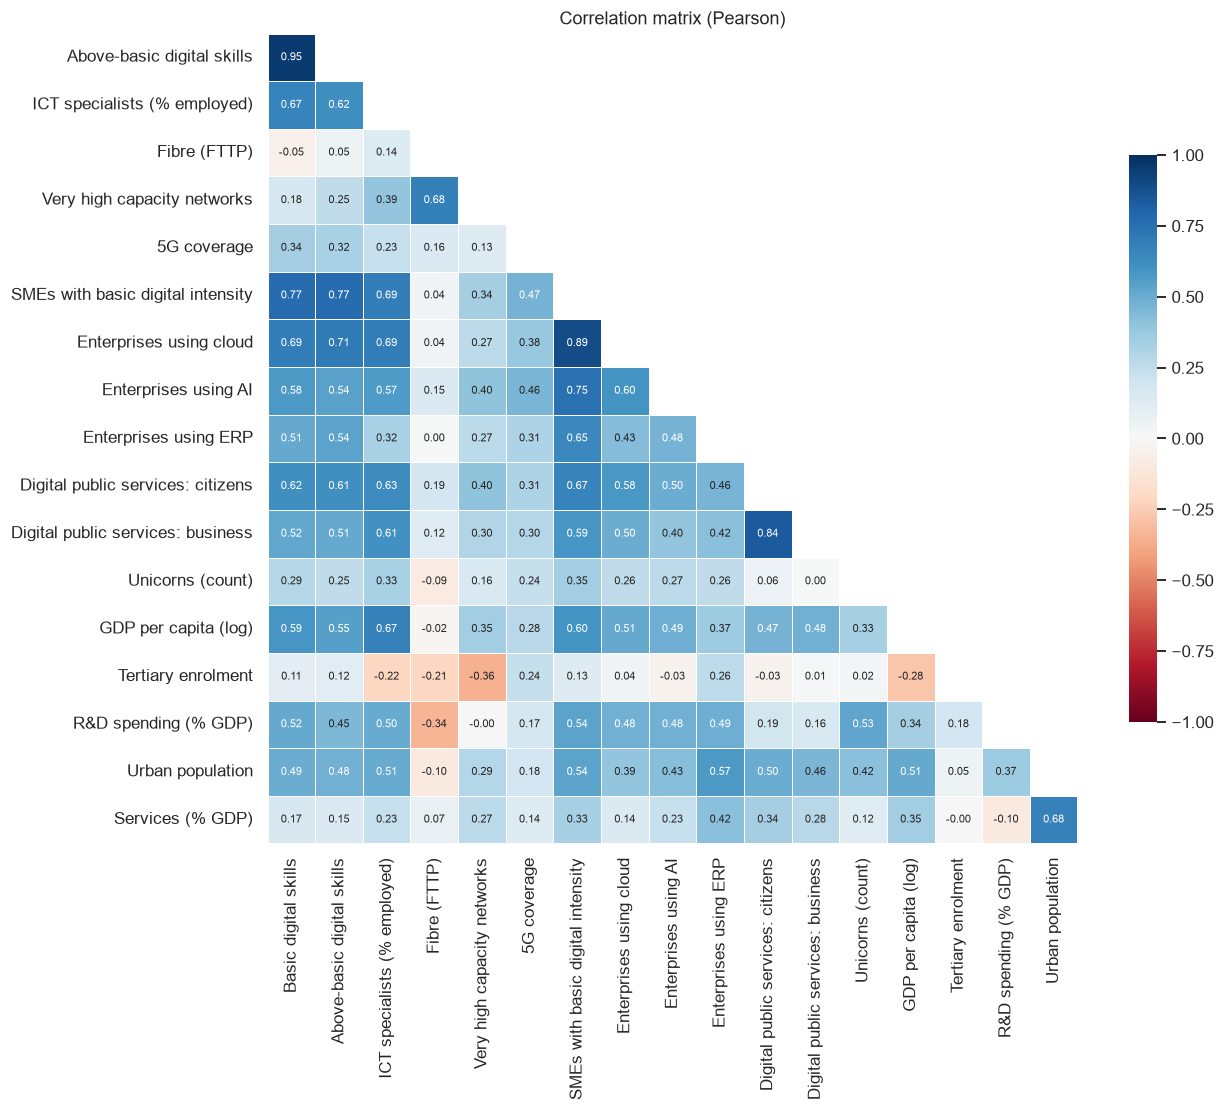

In [17]:
corr_cols = INDICATORS + (["log_gdp_pc_ppp", "tertiary_enrol", "rnd_gdp", "urban_pop", "services_gdp"] if HAS_WB else [])
corr = df[corr_cols].corr().rename(index=LABELS, columns=LABELS)

# Lower triangle: drop the first row and the last column (they would be empty)
corr_lower = corr.iloc[1:, :-1]
mask_upper = np.triu(np.ones(corr_lower.shape, dtype=bool), k=1)   # hides the part above the diagonal

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr_lower, mask=mask_upper, annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, annot_kws={"size": 7}, cbar_kws={"shrink": 0.7}, ax=ax)
ax.grid(False)
ax.set_title("Correlation matrix (Pearson)")
plt.tight_layout()
save_fig("05_correlation_matrix")
plt.show()

Below are the **most correlated pairs** (in absolute value) and how many exceed 0.85. Ask yourself: are they obvious pairs (for example two measures of skills) or surprising ones?

In [18]:
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
upper.index.name = "variable 1"
pairs = upper.reset_index().melt(id_vars="variable 1", var_name="variable 2", value_name="r").dropna()
pairs["|r|"] = pairs["r"].abs()

print("Pairs with |r| > 0.85:", int((pairs["|r|"] > 0.85).sum()), "out of", len(pairs))
display(pairs.sort_values("|r|", ascending=False).head(10).drop(columns="|r|").round(2).reset_index(drop=True))

Pairs with |r| > 0.85: 2 out of 153


,variable 1,variable 2,r
0,Basic digital skills,Above-basic digital skills,0.95
1,SMEs with basic digital intensity,Enterprises using cloud,0.89
2,Digital public services: citizens,Digital public services: business,0.84
3,Basic digital skills,SMEs with basic digital intensity,0.77
4,Above-basic digital skills,SMEs with basic digital intensity,0.77
5,SMEs with basic digital intensity,Enterprises using AI,0.75
6,Above-basic digital skills,Enterprises using cloud,0.71
7,ICT specialists (% employed),Enterprises using cloud,0.69
8,Basic digital skills,Enterprises using cloud,0.69
9,ICT specialists (% employed),SMEs with basic digital intensity,0.69


Finally, which variables are most closely related to the **Business index** (the prototype of the target)? We exclude its four component indicators, because they would be correlated by construction (circularity, as stated in the README).

In [19]:
explanatory = [c for c in corr_cols if c not in DIMENSIONS["Business"]]
with_target = df[explanatory].corrwith(scores["Business"]).sort_values(ascending=False)
display(with_target.rename(index=LABELS).round(2).to_frame("correlation with Business index"))

,correlation with Business index
Above-basic digital skills,0.75
Basic digital skills,0.75
ICT specialists (% employed),0.67
Digital public services: citizens,0.65
R&D spending (% GDP),0.58
GDP per capita (log),0.58
Urban population,0.57
Digital public services: business,0.56
5G coverage,0.47
Very high capacity networks,0.38


## 7. GDP per capita and business digitalisation

The chart relating a country's wealth to the digitalisation of its businesses (Business index), with a second chart for digital skills. Each point is a country in a year; the labels mark the countries in the latest year. The grey line is a trend line. On GDP the axis is logarithmic: for the same distance, the points represent the same *percentage* change in income.

Things to look at: is the relationship linear or does it flatten? Are there countries far above or far below the line, i.e. more (or less) digitalised than their income would predict? Those cases are the most interesting to discuss in the conclusions.

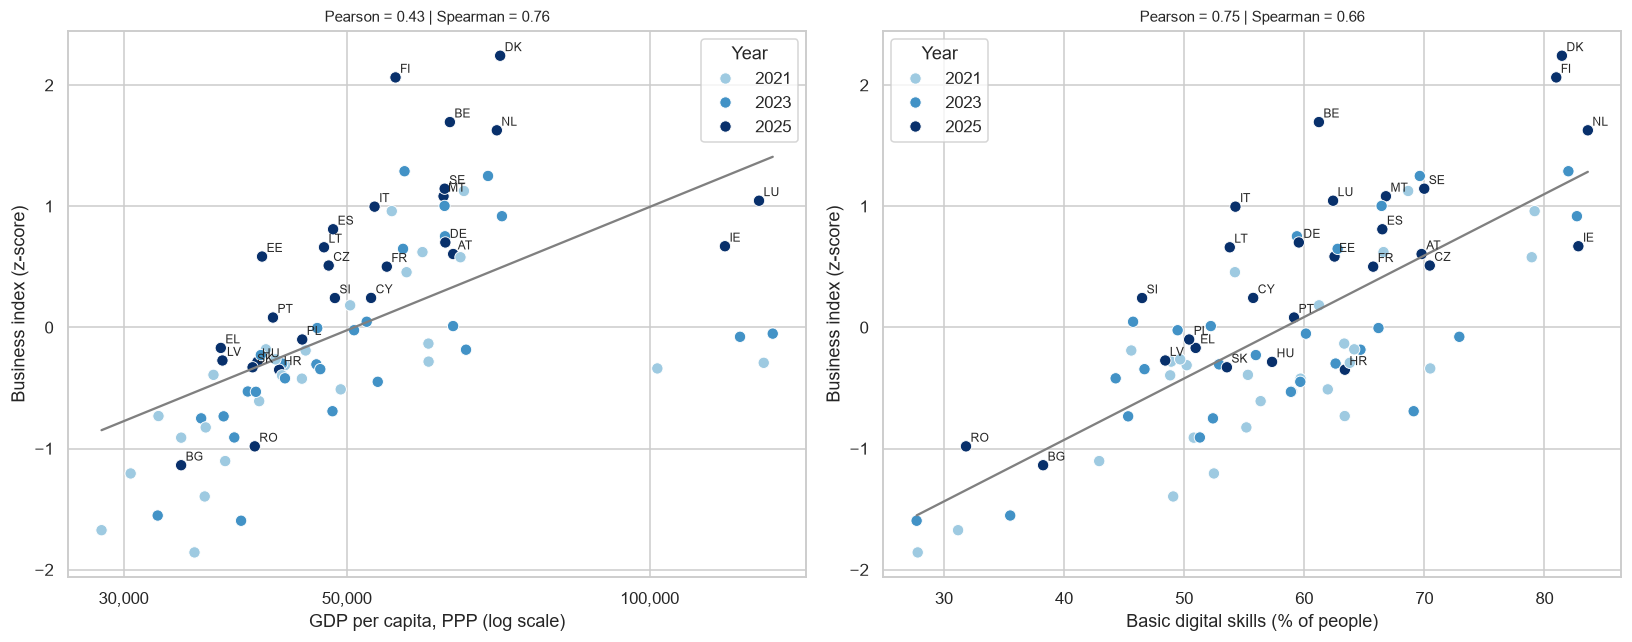

In [20]:
plot_df = df.assign(Business=scores["Business"])
year_colors = {2021: "#9ECAE1", 2023: "#4292C6", 2025: "#08306B"}

panels = [("skills_basic", "Basic digital skills (% of people)", False)]
if HAS_WB:
    panels.insert(0, ("gdp_pc_ppp", "GDP per capita, PPP (log scale)", True))
else:
    print("World Bank data not available: showing only the chart on skills.")

fig, axes = plt.subplots(1, len(panels), figsize=(7.5 * len(panels), 6))
axes = np.atleast_1d(axes)

for ax, (xcol, xlabel, logx) in zip(axes, panels):
    sns.scatterplot(data=plot_df, x=xcol, y="Business", hue="year", palette=year_colors, s=55, ax=ax)

    # trend line (on the log scale if requested)
    x = np.log(plot_df[xcol]) if logx else plot_df[xcol]
    slope, intercept = np.polyfit(x, plot_df["Business"], 1)
    xs = np.linspace(plot_df[xcol].min(), plot_df[xcol].max(), 100)
    ax.plot(xs, slope * (np.log(xs) if logx else xs) + intercept, color="grey", lw=1.5)

    last = plot_df[plot_df["year"] == plot_df["year"].max()]
    for _, row in last.iterrows():
        ax.annotate(row["country"], (row[xcol], row["Business"]), xytext=(3, 3),
                    textcoords="offset points", fontsize=8)
    if logx:
        ax.set_xscale("log")
        ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 3, 5)))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
        ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Business index (z-score)")
    ax.legend(title="Year")

    pearson = plot_df[[xcol, "Business"]].corr().iloc[0, 1]
    spearman = plot_df[[xcol, "Business"]].corr(method="spearman").iloc[0, 1]
    ax.set_title(f"Pearson = {pearson:.2f} | Spearman = {spearman:.2f}", fontsize=10)

plt.tight_layout()
save_fig("06_scatter_gdp_skills_vs_business")
plt.show()

**Pearson** measures the linear relationship; **Spearman** the one based on rank order (it is less sensitive to extreme values). If the two numbers are very different, there are usually outliers or a non-linear relationship.

## 8. What I noticed

*Write here in your own words (3-6 lines). An EDA is worth it if at the end you can tell what you learned.*

- **Structure and data quality:** ...
- **Distributions** (skewed indicators, ceiling effects, outliers): ...
- **Evolution 2021-2025** (what grew the most, what the least): ...
- **Rankings** (leading and lagging countries, unbalanced profiles, Italy's position): ...
- **Correlations** (highly correlated pairs, risk of multicollinearity): ...
- **GDP and digitalisation** (relationship, countries that deviate): ...
- **Hypotheses to test with the models:** ...

### Next steps
1. Save the notebook and commit (`git add .`, `git commit -m "Add exploratory data analysis"`, `git push`).
2. In the README update the status: *Exploratory analysis ✅* and add one or two charts from `outputs/figures/`.
3. Next notebook (`02_models.ipynb`): building the target, Ridge/Lasso baseline, Random Forest and country-grouped validation.